# CivicFlux — Model Comparison and Validation

## 01. Research objective and comparison rules

Audit what the existing CivicFlux components actually achieve using their saved artifacts and predictions. No estimator is retrained here. A rainfall MAE in mm/day cannot be ranked against a traffic MAE in vehicles/hour or a flood classification F1. Instead, verify each task's arithmetic and compare with its own documented baseline.

Distinguish forecast research, synthetic surrogates, unsupervised measurement alerts, graph rules and constrained optimization. Technical inference readiness means that a fresh-process loading/prediction check passed; it does not establish municipal validity. The water model remains explicitly unsupported for operational fault prediction, and outcome success scores cannot drive allocation.

### Reproducible read-only evaluation environment

The new report directory contains evaluation outputs only. Source notebooks 01–05 and legacy model files are not rewritten.

In [1]:
from pathlib import Path
import sys,json,platform,subprocess,copy
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from IPython.display import display
ROOT=Path.cwd() if (Path.cwd()/'civicflux_core.py').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from civicflux_core import sha256
from src.civicflux.serving import discover,directory_for,json_safe,SCOPES,UNITS,HORIZONS
from src.civicflux.validation import recompute_metrics,artifact_inventory,component_comparisons,registry_with_checks
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.figsize':(11,4),'figure.dpi':110})
print('Python',platform.python_version(),'project',ROOT)

OUT=ROOT/'artifacts/model_validation/v1.0.0';OUT.mkdir(parents=True,exist_ok=True)
REPORTS=ROOT/'reports/integration'

Python 3.13.5 project /Users/jiyahooda/Documents/New project/civicflux_ml


## 02. Artifact discovery and component taxonomy

Discover the latest versioned experiment for every expected component. Legacy forecasts have no semantic artifact version, so their registry version is honestly recorded as `legacy-unversioned`. Infrastructure anomaly detection stores a model card instead of metadata.json; the registry recognizes that existing architecture. Missing files remain missing rather than being generated as replacements.

### Discover components and actual notebook coverage

The registry locates existing fitted artifacts, metadata, schema and model type. Optimization is not a trained ML model.

In [2]:
registry=registry_with_checks(ROOT,REPORTS)
summary=pd.DataFrame(registry)
display(summary[['component','component_kind','version','selected_model','artifact','missing']])
import nbformat
notebook_rows=[]
for prefix in range(1,10):
    matches=list((ROOT/'notebooks').glob(f'{prefix:02d}_*.ipynb'))
    if not matches:notebook_rows.append({'notebook':prefix,'status':'missing'});continue
    book=nbformat.read(matches[0],as_version=4)
    errors=[o.get('ename') for c in book.cells if c.cell_type=='code' for o in c.get('outputs',[]) if o.output_type=='error']
    notebook_rows.append({'notebook':matches[0].name,'cells':len(book.cells),'executed_cells':sum(c.cell_type=='code' and c.execution_count is not None for c in book.cells),'error_outputs':len(errors)})
notebook_inventory=pd.DataFrame(notebook_rows);display(notebook_inventory)
notebook_inventory.to_csv(OUT/'notebook_inventory.csv',index=False)

,component,component_kind,version,selected_model,artifact,missing
0,rainfall,supervised time-series regression,legacy-unversioned,Random Forest tuned,artifacts/rainfall/pipeline.joblib,[]
1,aqi,supervised time-series regression,legacy-unversioned,Ridge tuned,artifacts/aqi/pipeline.joblib,[]
2,traffic,supervised time-series regression,legacy-unversioned,XGBoost tuned,artifacts/traffic/pipeline.joblib,[]
3,flood,supervised simulator,legacy-unversioned,XGBoost tuned,artifacts/flood/pipeline.joblib,[]
4,infrastructure_anomaly,unsupervised detectors + data-quality rules,1.0.0,not a supervised selected model,artifacts/infrastructure_anomaly/v1.0.0/detect...,[]
5,water_network,supervised time-series regression,1.1.0,Logistic tuned,artifacts/water_network/v1.1.0/pipeline.joblib,[]
6,cascade_risk,supervised simulator + graph rules,1.1.0,Logistic tuned,artifacts/cascade_risk/v1.1.0/pipeline.joblib,[]
7,resource_optimization,CP-SAT optimization + greedy rules,1.1.0,not a supervised selected model,None,[]
8,intervention_outcomes,synthetic classification + duration regression,1.1.0,Random Forest,artifacts/intervention_outcomes/v1.1.0/pipelin...,[]


,notebook,cells,executed_cells,error_outputs
0,01_Rainfall_Research.ipynb,107,46,0
1,02_AQI_Research.ipynb,105,45,0
2,03_Traffic_Research.ipynb,107,46,0
3,04_Flood_Research.ipynb,99,42,0
4,05_Infrastructure_Anomaly_Research.ipynb,129,57,0
5,06_Water_Network_Fault_Research.ipynb,78,32,0
6,07_Cascade_Risk_Analysis.ipynb,74,30,0
7,08_Sustainability_and_Resource_Optimization.ipynb,52,22,0
8,09_Intervention_Outcomes.ipynb,71,30,0


### Inventory every component artifact and its fingerprint

Hashes make later changes visible and keep old v1.0.0 experiments distinct from the targeted v1.1.0 review. Generated evaluation reports are excluded to avoid self-referential hashes.

,path,bytes,suffix,sha256
0,artifacts/aqi/Ridge_search.csv,2159,.csv,9e92a3506fe6d679908cc295ca14963f4843567c49671e...
1,artifacts/aqi/XGBoost_search.csv,3215,.csv,f668760890d3b6d93abbb7e5b5dbf17f4c0ce4531f0e0d...
2,artifacts/aqi/candidate_cv.csv,1095,.csv,d4e0ac6c85ba065c9189a822ed891f71c765569361f0c8...
3,artifacts/aqi/civicflux_payload.json,602,.json,455f421bf2a8b5f62b957b0c26001f10bda238dbe35777...
4,artifacts/aqi/cleaning_audit.json,218,.json,15cf7095664b916605b1a2cde45b3e180ba6ce67aeacd9...
5,artifacts/aqi/feature_dictionary.csv,411,.csv,80ab4369ae12c0a0641d01ae1769d9dc0fc975a67f5f76...
6,artifacts/aqi/feature_schema.json,1856,.json,1ec56ac77d53da3a424e16ecd64ac0c9e199007ce3b256...
7,artifacts/aqi/metadata.json,1098,.json,4678113feab222d2950aebef3d6abe739202ca24a31fef...
8,artifacts/aqi/metrics.json,168,.json,99738f47ff7abf43405cbc0367ce5202ce8bd9140bcdae...
9,artifacts/aqi/next_interval_forecast.csv,181,.csv,5843701388f28afccdd46d181bb1ac148ed3eb68191b03...


,files,total_bytes
suffix,,
.csv,137,21621546
.joblib,11,13096790
.json,75,895202
.txt,1,2995


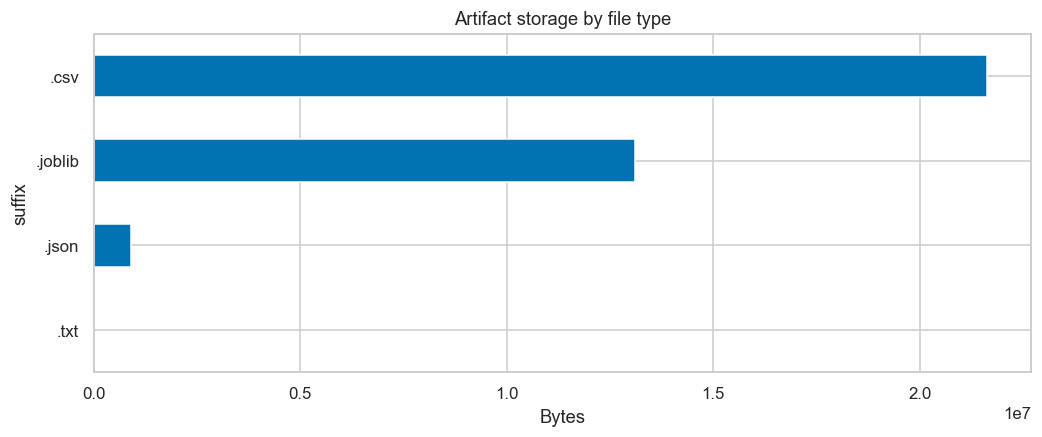

In [3]:
inventory=artifact_inventory(ROOT);display(inventory.head(20))
display(inventory.groupby('suffix').agg(files=('path','size'),total_bytes=('bytes','sum')))
inventory.to_csv(OUT/'artifact_inventory.csv',index=False)
inventory.groupby('suffix')['bytes'].sum().sort_values().plot.barh(title='Artifact storage by file type');plt.xlabel('Bytes');plt.show()

## 03. Dataset provenance and geographic support

Rainfall uses a Delhi state aggregate. AQI is a publisher-described Delhi aggregate with incomplete source units and station lineage. Traffic junctions lack a city, coordinates and timezone. These are distinct entities and cannot be joined on a city name. BattLeDIM/L-TOWN is simulated; cascade, drainage and outcome experiments are synthetic. The optimizer receives hypothetical costs, inventory and policy proxies.

A high score on synthetic data measures behavior under the stated generator. It is not measured accuracy on Delhi equipment failures, flood incidents, civic cascades or intervention success.

### Make scope, provenance and horizon visible

The matrix preserves uncertainty in provenance rather than labeling all downloaded data verified real.

,component,geographic_scope,units,horizon,provenance,validation_status,simulation_only
0,rainfall,Delhi state aggregate,mm/day,next day,reported real state aggregate; upstream lineag...,research; measurement lineage and reporting de...,False
1,aqi,Delhi aggregate (station lineage unverified),ug/m3 (working assumption; source unit metadat...,next hour PM2.5,publisher-described measurements; station line...,research; measurement lineage and reporting de...,False
2,traffic,unlocated benchmark junctions,vehicles/hour,next hour vehicle count,"observational benchmark; city, coordinates and...",research; measurement lineage and reporting de...,False
3,flood,hypothetical catchments with state-rainfall re...,"{'rain_mm': 'mm', 'duration_h': 'hours', 'area...",24-hour simulated scenario,see source-specific metadata/model card,research scenario surrogate; not validated rea...,True
4,infrastructure_anomaly,source-specific unmapped benchmark sensors,per registered sensor,contemporaneous unusual measurement,see source-specific metadata/model card,research evidence only,False
5,water_network,L-TOWN simulated network only,"{'pressure': 'm', 'flow': 'm3/h', 'level': 'm'}",onset during preceding 24 hours,BattLeDIM CC BY 4.0 simulated SCADA,weak temporal benchmark; operational abstention,True
6,cascade_risk,synthetic civic dependency graphs,unitless simulated risk,next 60 minutes,seeded independent-cascade simulator,unseen synthetic graph holdout; no municipal v...,True
7,resource_optimization,synthetic intervention scenarios,"{'budget': 'hypothetical INR', 'crew_hours': '...",simultaneous planning window,"documented fictional costs, resources and poli...",scenario feasibility verified; no real resourc...,True
8,intervention_outcomes,synthetic intervention records only,"{'cost': 'hypothetical INR', 'duration': 'hours'}",completed synthetic outcome,"seeded, confounded outcome generator; no real ...",chronological synthetic holdout; unsupported s...,True


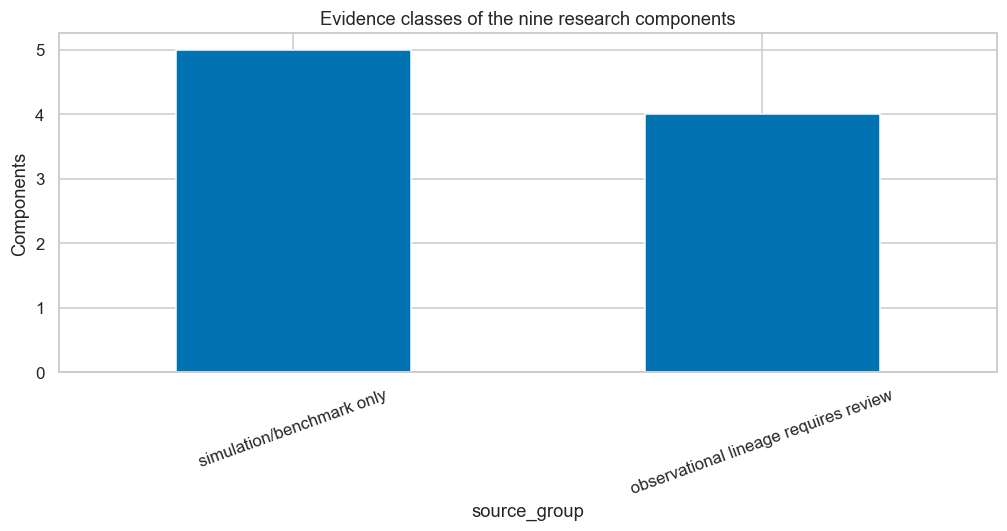

In [4]:
provenance=summary[['component','geographic_scope','units','horizon','provenance','validation_status','simulation_only']].copy()
display(provenance);provenance.to_csv(OUT/'provenance_and_scope.csv',index=False)
status_counts=summary.assign(source_group=np.where(summary.simulation_only,'simulation/benchmark only','observational lineage requires review')).source_group.value_counts()
status_counts.plot.bar(title='Evidence classes of the nine research components',rot=20);plt.ylabel('Components');plt.show()

## 04. Validation design and information availability

Forecasts use chronological development, calibration and final periods with horizon purging; no random future/past shuffle. Water uses 2018 training/validation and 2019 testing, with onset-window boundary exclusions. Cascade splits independent event groups and holds out complete graph seeds, though all labels still follow the same simulator family. Outcomes split assignment time; post-completion and verification fields are forbidden as predictors.

The targeted review repairs water threshold coverage, retains cascade Logistic Regression, and moves duration selection from test to validation. Test-based diagnostics do not authorize another selection round.

### Inspect existing split and event records

Print the stored designs, not an invented uniform cross-validation claim.

In [5]:
for component,filename in [('rainfall','split_boundaries.csv'),('aqi','split_boundaries.csv'),('traffic','split_boundaries.csv'),('flood','splits.csv'),('water_network','splits.csv')]:
    path=directory_for(ROOT,component)/filename
    print(component);display(pd.read_csv(path) if path.exists() else pd.DataFrame({'warning':['split file unavailable']}))
validation_notes=pd.DataFrame([
 ('rainfall/aqi/traffic','chronological, purged horizon','source latency and lineage unverified'),
 ('flood','forcing-date grouped chronological','uncalibrated synthetic hydrology'),
 ('anomaly','historical fit, later observations and injection fixtures','no verified equipment-fault labels'),
 ('water','2018 train/validation; 2019 test','only two validation onsets; temporal shift'),
 ('cascade','event grouped; unseen graph seeds','same synthetic mechanism family'),
 ('optimizer','identical hard constraints across methods','synthetic costs and equity/environment assumptions'),
 ('outcomes','chronological assignment; validation-only duration choice','synthetic noisy, confounded and completion-selected')],columns=['component','design','limitation'])
display(validation_notes);validation_notes.to_csv(OUT/'validation_design.csv',index=False)

rainfall


,split,rows,origin_start,origin_end,last_label
0,development,3293,2009-01-31 00:00:00+05:30,2018-02-05 00:00:00+05:30,2018-02-06 00:00:00+05:30
1,calibration,1097,2018-02-07 00:00:00+05:30,2021-02-25 00:00:00+05:30,2021-02-26 00:00:00+05:30
2,test,1098,2021-02-27 00:00:00+05:30,2024-03-19 00:00:00+05:30,2024-03-20 00:00:00+05:30


aqi


,split,rows,origin_start,origin_end,last_label
0,development,26192,2019-01-08 00:00:00+05:30,2022-01-03 07:00:00+05:30,2022-01-03 08:00:00+05:30
1,calibration,8730,2022-01-03 09:00:00+05:30,2023-01-02 02:00:00+05:30,2023-01-02 03:00:00+05:30
2,test,8732,2023-01-02 04:00:00+05:30,2023-12-31 23:00:00+05:30,2024-01-01 00:00:00+05:30


traffic


...

flood


,split,rows,forcing_dates,prevalence,start,end
0,dev,13244,3311,0.006494,2009-01-01 00:00:00+05:30,2018-01-24 00:00:00+05:30
1,cal,4412,1103,0.006120,2018-01-26 00:00:00+05:30,2021-02-19 00:00:00+05:30
2,test,4420,1105,0.011312,2021-02-21 00:00:00+05:30,2024-03-20 00:00:00+05:30


water_network


,split,n,positive,start,end
0,train,5808,288,2018-01-02 00:00:00,2018-08-31 23:00:00
1,validation,2928,48,2018-09-01 00:00:00,2018-12-31 23:00:00
2,test,8760,456,2019-01-01 00:00:00,2019-12-31 23:00:00


,component,design,limitation
0,rainfall/aqi/traffic,"chronological, purged horizon",source latency and lineage unverified
1,flood,forcing-date grouped chronological,uncalibrated synthetic hydrology
2,anomaly,"historical fit, later observations and injecti...",no verified equipment-fault labels
3,water,2018 train/validation; 2019 test,only two validation onsets; temporal shift
4,cascade,event grouped; unseen graph seeds,same synthetic mechanism family
5,optimizer,identical hard constraints across methods,synthetic costs and equity/environment assumpt...
6,outcomes,chronological assignment; validation-only dura...,"synthetic noisy, confounded and completion-sel..."


## 05. Recompute metrics from saved predictions

Recompute applicable regression and classification metrics from labels and scores already saved by earlier notebooks. Reported values are compared with a small numerical tolerance for CSV serialization. Persistence reproduces the original training-mean fallback when a current observation is missing; it does not use test-label information.

Flood exports calibrated probabilities but not raw probabilities. Its raw Brier score cannot be recomputed from that file, and is explicitly marked unavailable. No missing metric is fabricated.

### Arithmetic consistency audit

A mismatch is a reportable finding. This notebook will not silently replace a reported metric.

In [6]:
metric_checks,forecast_baselines=recompute_metrics(ROOT)
display(metric_checks);display(metric_checks[metric_checks.status.ne('consistent')])
metric_checks.to_csv(OUT/'metric_consistency.csv',index=False)
forecast_baselines.to_csv(OUT/'forecast_baselines.csv',index=False)
print('Consistent:',int(metric_checks.status.eq('consistent').sum()),'mismatches:',int(metric_checks.status.eq('MISMATCH').sum()))
assert not metric_checks.status.eq('MISMATCH').any(),'Investigate actual saved-metric inconsistencies'

,component,metric,reported,recomputed,absolute_difference,status
0,rainfall,MAE,2.691146,2.691146,0.000000e+00,consistent
1,rainfall,RMSE,7.779361,7.779361,0.000000e+00,consistent
2,rainfall,R2,0.109983,0.109983,0.000000e+00,consistent
3,rainfall,bias,-0.306694,-0.306694,0.000000e+00,consistent
4,rainfall,MAE_skill_vs_persistence,0.083667,0.083667,0.000000e+00,consistent
5,aqi,MAE,12.793959,12.793959,0.000000e+00,consistent
6,aqi,RMSE,15.967040,15.967040,0.000000e+00,consistent
7,aqi,R2,0.700145,0.700145,0.000000e+00,consistent
8,aqi,bias,0.237991,0.237991,0.000000e+00,consistent
9,aqi,MAE_skill_vs_persistence,0.292352,0.292352,0.000000e+00,consistent


,component,metric,reported,recomputed,absolute_difference,status
17,flood,Brier_raw,0.002063,NaN,NaN,not recomputable from saved predictions


Consistent: 54 mismatches: 0


## 06. Forecasts versus their own baselines

Compare a forecast with persistence on exactly the same task, units and test rows. Positive MAE skill means improvement over that task's persistence baseline. It does not imply an operational benefit and is not a cross-domain ranking. Current measurements are assumed available at the origin; real reporting delay may reduce achievable skill.

### Separate unit-specific forecast panels

Each panel uses its own physical units and axis. The dimensionless skill chart compares relative baseline improvement only.

,component,model_MAE,baseline_MAE,baseline,fallback_count,units,paired_n,MAE_skill
0,rainfall,2.691146,2.936866,persistence; training-mean fallback for missin...,15,mm/day,1098,0.083667
1,aqi,12.793959,18.079559,persistence; training-mean fallback for missin...,0,ug/m3 (working assumption; source unit metadat...,8732,0.292352
2,traffic,3.249163,3.805633,persistence; training-mean fallback for missin...,0,vehicles/hour,11540,0.146222


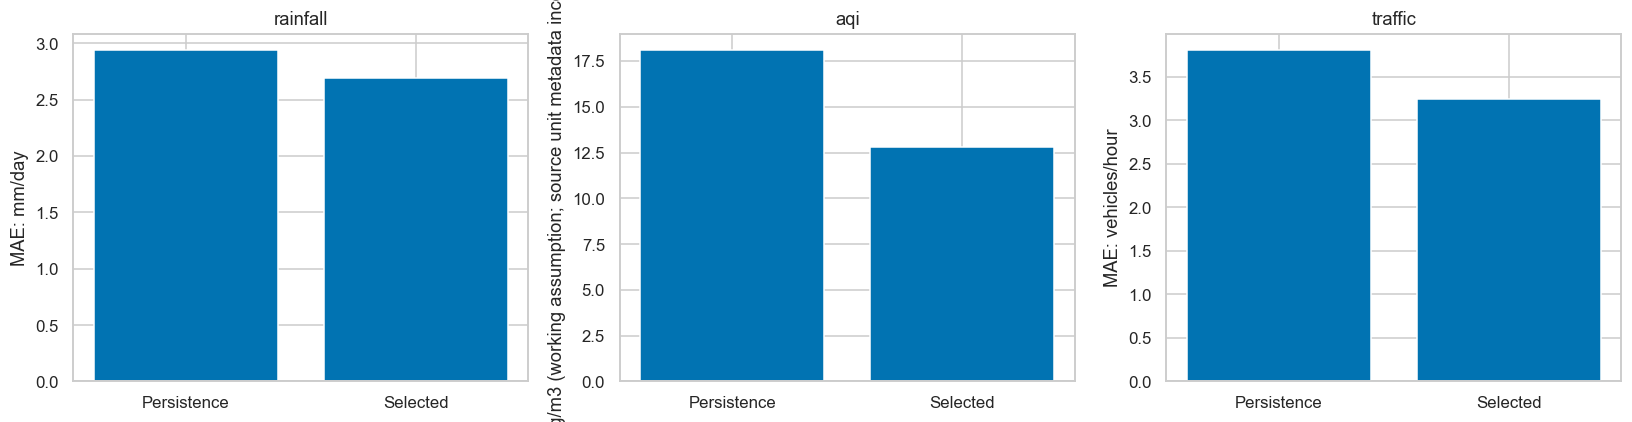

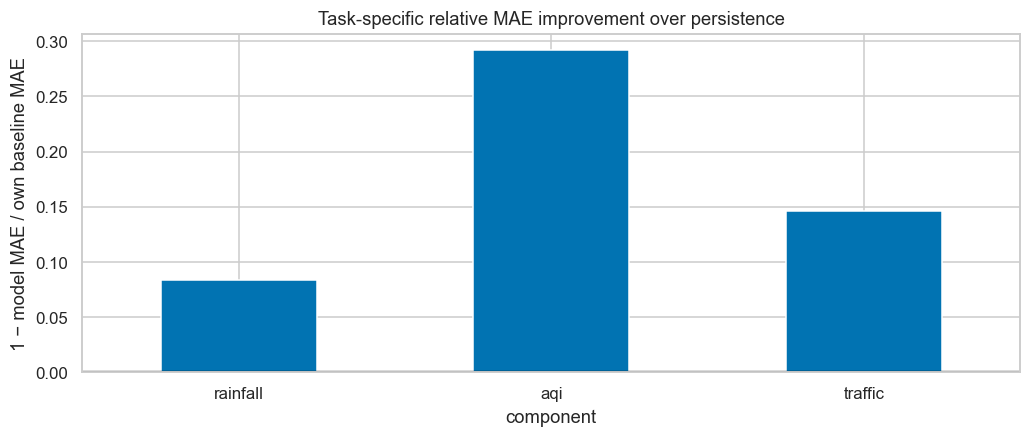

In [7]:
display(forecast_baselines)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,row in zip(axes,forecast_baselines.itertuples()):
    ax.bar(['Persistence','Selected'],[row.baseline_MAE,row.model_MAE]);ax.set_title(row.component);ax.set_ylabel('MAE: '+row.units)
plt.tight_layout();plt.show()
forecast_baselines.set_index('component').MAE_skill.plot.bar(title='Task-specific relative MAE improvement over persistence',rot=0);plt.axhline(0,color='black');plt.ylabel('1 − model MAE / own baseline MAE');plt.show()

### Inspect uncertainty coverage and extreme errors

Intervals are pooled calibration residual bands. Observed marginal coverage does not guarantee conditional coverage for rare extreme events.

,component,n,coverage_90,extreme_95_coverage,mean_width,extreme_n
0,rainfall,1098,0.880692,0.090909,6.984046,55
1,aqi,8732,0.908612,0.647597,52.585144,437
2,traffic,11540,0.864991,0.172757,11.071998,602


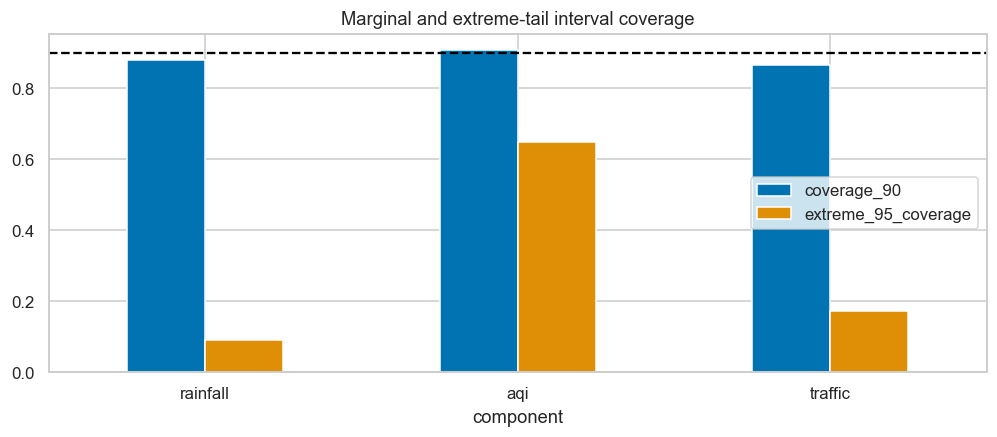

In [8]:
interval_rows=[]
for component in ['rainfall','aqi','traffic']:
    p=pd.read_csv(directory_for(ROOT,component)/'test_predictions.csv')
    if {'lower','upper'}.issubset(p.columns):
        covered=p.target.between(p.lower,p.upper)
        extreme=p.target>=p.target.quantile(.95)
        interval_rows.append({'component':component,'n':len(p),'coverage_90':float(covered.mean()),'extreme_95_coverage':float(covered[extreme].mean()),'mean_width':float((p.upper-p.lower).mean()),'extreme_n':int(extreme.sum())})
intervals=pd.DataFrame(interval_rows);display(intervals);intervals.to_csv(OUT/'interval_coverage.csv',index=False)
intervals.plot.bar(x='component',y=['coverage_90','extreme_95_coverage'],rot=0,title='Marginal and extreme-tail interval coverage');plt.axhline(.9,color='black',ls='--');plt.show()

## 07. Classification, graph rules and weak alert policies

Each classification comparison has its own target and population. Flood scores mimic a drainage simulator. Water scores detect recent simulated onsets with high false-alert burden. Cascade scores emulate a stochastic dependency mechanism. Outcome success scores have weak discrimination and must not supply allocation weights. Do not combine their F1 or ROC-AUC values into a single winner.

### Task-specific baseline tables

Every metric shown is read or recomputed from the existing experiment. Graph rules and historical-rate baselines keep their own semantics.

water_network


,model,threshold,selection_period,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,Selected ML,0.018470,2018 validation,0.062346,0.666667,0.114029,0.064881,0.577279,0.049972,0.550578,4572,152,8760,0.052055
1,Train prior,0.049587,2018 validation,0.052055,1.000000,0.098958,0.052055,0.500000,0.049351,1.000000,8304,0,8760,0.052055
2,Hydraulic changes,0.066427,2018 validation,0.053096,0.804825,0.099620,0.050821,0.497434,0.106171,0.788174,6545,89,8760,0.052055
3,Seasonal directional residual,0.921323,2018 validation,0.049180,0.526316,0.089955,0.049231,0.485344,0.711617,0.558767,4640,216,8760,0.052055


cascade_risk


,method,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,Logistic tuned,0.316444,0.788749,0.451677,0.461236,0.893923,0.066500,0.179901,1484,184,9120,0.095504
1,NetworkX reachability,0.206105,1.000000,0.341770,0.206105,0.796642,0.367873,0.406716,3355,0,9120,0.095504


resource_optimization


,scenario,method,status,utility,selected_count,budget_used,pump_use,solver_seconds,approval_required,dispatch_allowed,budget_utilization,incident_coverage
0,normal,severity_greedy,HEURISTIC_FEASIBLE,11.225591,17,149353,6,0.000127,True,False,0.995687,0.53125
1,normal,utility_greedy,HEURISTIC_FEASIBLE,10.902363,16,146498,5,0.000096,True,False,0.976653,0.50000
2,normal,CP-SAT,OPTIMAL,12.418516,21,149215,8,0.020408,True,False,0.994767,0.65625
3,budget_scarce,severity_greedy,HEURISTIC_FEASIBLE,5.053989,7,54837,3,0.000102,True,False,0.997036,0.21875
4,budget_scarce,utility_greedy,HEURISTIC_FEASIBLE,5.752837,8,54790,3,0.000088,True,False,0.996182,0.25000
5,budget_scarce,CP-SAT,OPTIMAL,6.731123,11,54718,3,0.001971,True,False,0.994873,0.34375
6,pump_shortage,severity_greedy,HEURISTIC_FEASIBLE,8.028084,12,97216,2,0.000106,True,False,0.972160,0.37500
7,pump_shortage,utility_greedy,HEURISTIC_FEASIBLE,8.138415,12,99968,2,0.000096,True,False,0.999680,0.37500
8,pump_shortage,CP-SAT,OPTIMAL,9.225179,15,97549,2,0.002415,True,False,0.975490,0.46875
9,crew_shortage,severity_greedy,HEURISTIC_FEASIBLE,6.067082,9,72111,4,0.000103,True,False,0.721110,0.28125


intervention_outcomes


,model,threshold,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,Selected classifier,0.507379,0.600000,0.530831,0.563300,0.618917,0.570787,0.257404,0.424437,132,175,684,0.545322
1,Constant 0.5,0.500000,0.000000,0.000000,0.000000,0.545322,0.500000,0.250000,0.000000,0,373,684,0.545322
2,Training success rate,0.529549,0.000000,0.000000,0.000000,0.545322,0.500000,0.248195,0.000000,0,373,684,0.545322
3,Historical type rate,0.590909,0.582734,0.651475,0.615190,0.575832,0.545598,0.251189,0.559486,174,130,684,0.545322
4,Generator oracle (not deployable),0.622459,0.678392,0.361930,0.472028,0.648775,0.612782,0.238740,0.205788,64,238,684,0.545322


flood


,model,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,selected simulated flood classifier,0.653333,0.98,0.784,0.897110,0.998908,0.002423,0.00595,26,1,4420,0.011312
1,training prior,0.000000,0.00,0.000,0.011312,0.500000,0.011207,0.00000,0,50,4420,0.011312


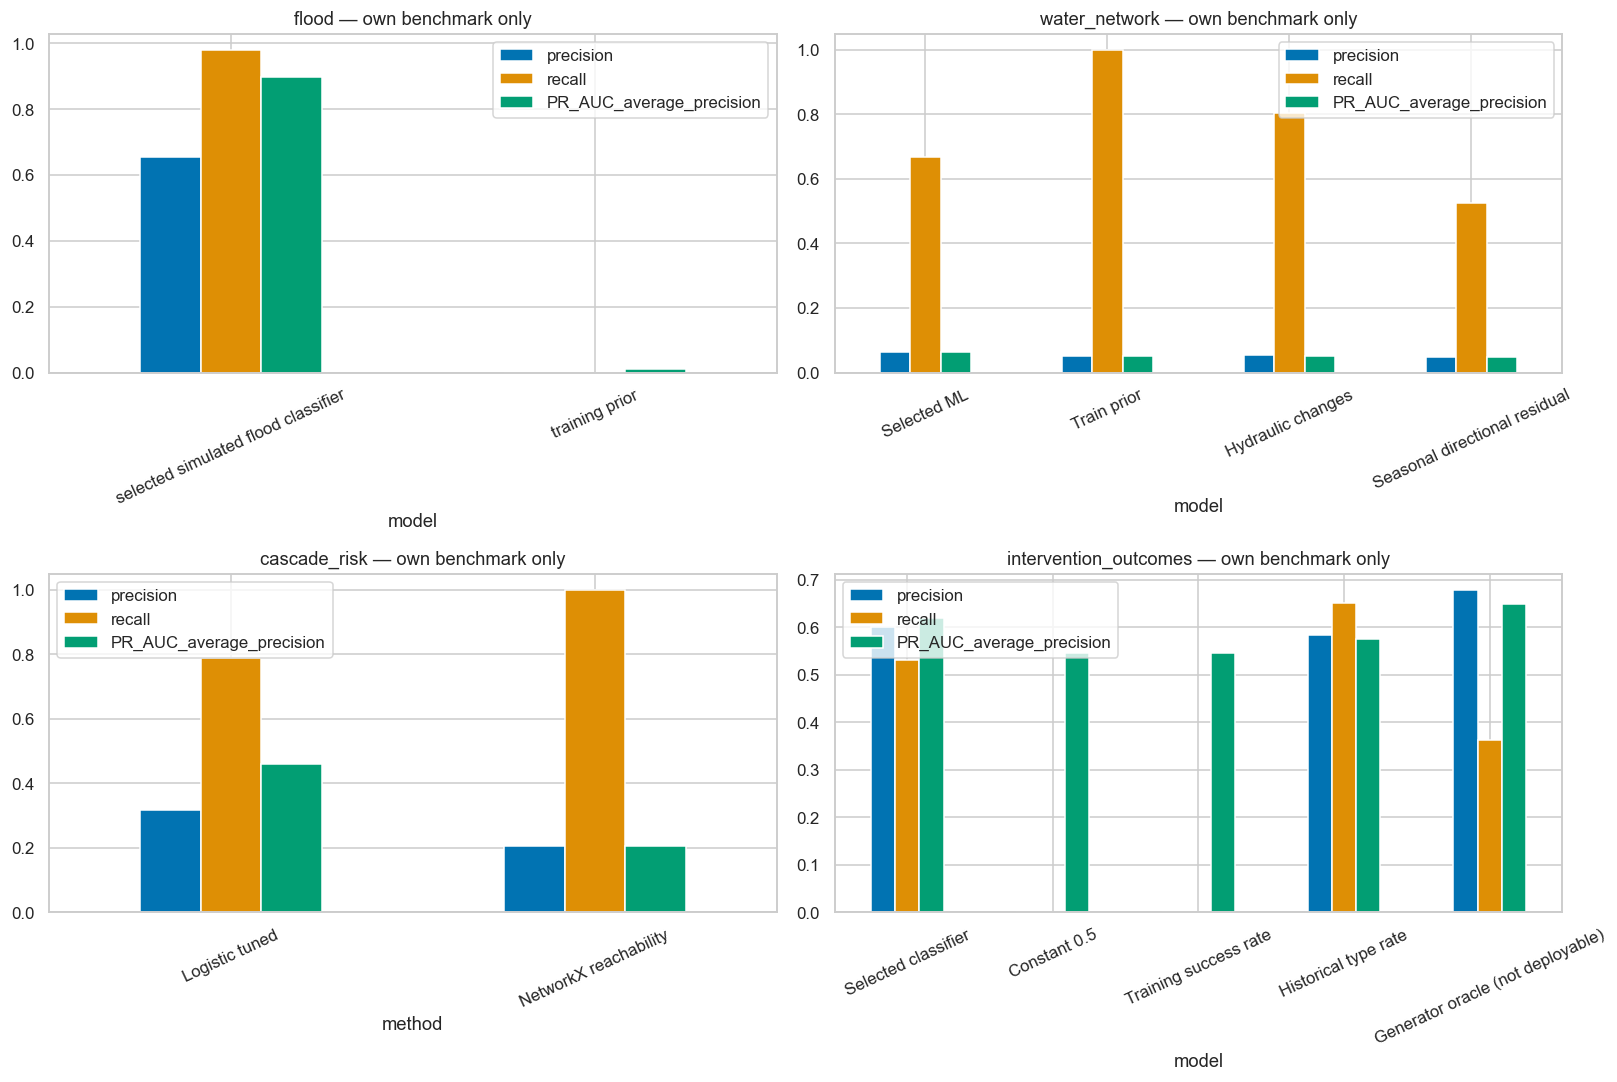

In [9]:
comparisons=component_comparisons(ROOT)
for component,table in comparisons.items():
    print(component);display(table)
    table.to_csv(OUT/(component+'_baseline_comparison.csv'),index=False)
fig,axes=plt.subplots(2,2,figsize=(15,10))
for ax,component in zip(axes.flat,['flood','water_network','cascade_risk','intervention_outcomes']):
    table=comparisons[component];label='method' if 'method' in table else 'model'
    fields=[c for c in ['precision','recall','PR_AUC_average_precision'] if c in table]
    table.plot.bar(x=label,y=fields,ax=ax,rot=25,title=component+' — own benchmark only')
plt.tight_layout();plt.show()

### Water events and false-alarm duration

Always-alert baselines can recover every event while wasting almost every negative hour. Event recall therefore appears beside false-alert duration and episode counts.

,model,events,recovered_events,event_recall,median_delay_hours_detected_only,alert_hours,false_alert_hours,false_alert_hours_per_negative_day,alert_episodes,false_alarm_episodes,false_alarm_episodes_per_30_days
0,Selected ML,19,17,0.894737,0.500000,4876,4572,13.213873,202,180,14.794521
1,Train prior,19,19,1.000000,0.333333,8760,8304,24.000000,1,0,0.000000
2,Hydraulic changes,19,19,1.000000,0.583333,6912,6545,18.916185,1183,1111,91.315068
3,Seasonal directional residual,19,15,0.789474,0.750000,4880,4640,13.410405,372,345,28.356164


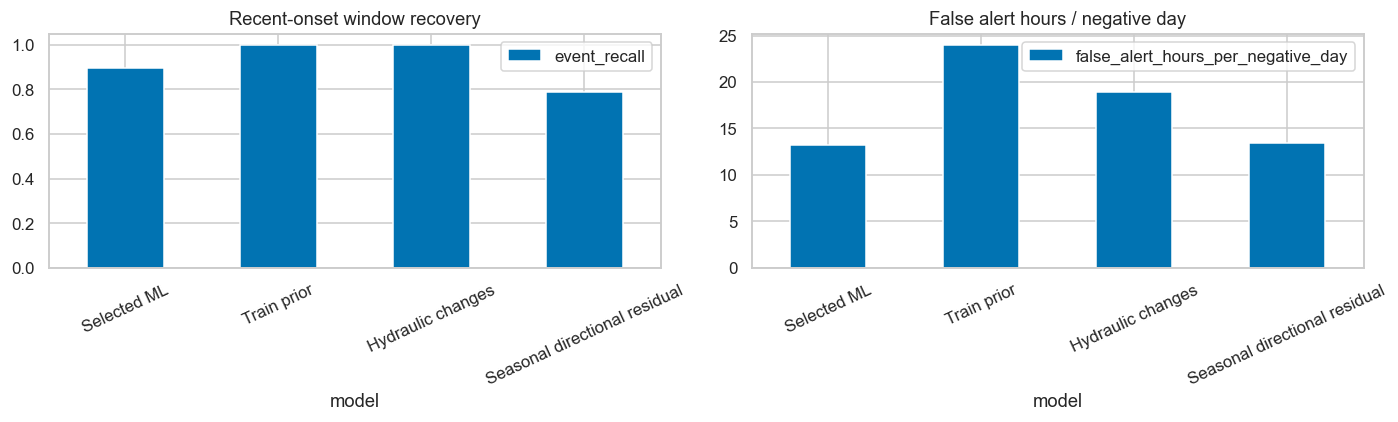

In [10]:
water_events=pd.read_csv(directory_for(ROOT,'water_network')/'event_comparison.csv');display(water_events)
water_events.to_csv(OUT/'water_event_review.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(13,4))
water_events.plot.bar(x='model',y='event_recall',ax=ax[0],rot=25)
water_events.plot.bar(x='model',y='false_alert_hours_per_negative_day',ax=ax[1],rot=25)
ax[0].set_title('Recent-onset window recovery');ax[1].set_title('False alert hours / negative day');plt.tight_layout();plt.show()

## 08. Anomaly detection and resource optimization

Unlabeled unusual measurements cannot support real-fault precision or accuracy. Anomaly fixture recovery measures response to deliberately injected perturbations only. Resource allocation is an optimization problem: compare utility, capacity use and constraint satisfaction under shared synthetic constraints, without calling the solver a classifier.

### Inspect anomaly evidence without inventing fault labels

The outputs preserve the separation between historical alert rates and injected anomaly recovery.

test_alert_rates.csv


,sensor,rule_alert,robust_alert,isolation_alert,quality_alert,review_alert
0,aqi:Delhi,0.009812,0.000000,0.017798,0.000000,0.017798
1,rainfall:Delhi,0.148376,0.136084,0.040386,0.129939,0.170325
2,traffic:1,0.348750,0.000685,0.666324,0.000000,0.666324
3,traffic:2,0.501884,0.001713,0.830079,0.000000,0.830079
4,traffic:3,0.010963,0.002741,0.028092,0.000000,0.028092


injected_summary.csv


,mechanism,detector,recovery,event_detection,median_delay,matched_clean_alert,new_alert_fraction,background_alert
0,data_gap,isolation,0.000000,0.000000,NaN,0.211310,0.000000,0.277349
1,data_gap,review,1.000000,1.000000,0.0,0.211310,0.788690,0.373821
2,data_gap,robust,0.000000,0.000000,NaN,0.173611,0.000000,0.037225
3,data_gap,rule,1.000000,1.000000,0.0,0.158730,0.841270,0.243449
4,drift,isolation,0.672619,1.000000,3.0,0.211310,0.461310,0.280888
5,drift,review,0.672619,1.000000,3.0,0.211310,0.461310,0.377361
6,drift,robust,0.361111,0.500000,0.0,0.173611,0.187500,0.036576
7,drift,rule,0.494048,1.000000,5.0,0.158730,0.359127,0.244603
8,flatline,isolation,0.451389,0.666667,7.0,0.211310,0.263889,0.280532
9,flatline,review,0.652778,1.000000,5.0,0.211310,0.465278,0.377004


Verified municipal fault precision/recall: unavailable; no real fault labels.


,scenario,method,status,utility,selected_count,budget_utilization
0,normal,severity_greedy,HEURISTIC_FEASIBLE,11.225591,17,0.995687
1,normal,utility_greedy,HEURISTIC_FEASIBLE,10.902363,16,0.976653
2,normal,CP-SAT,OPTIMAL,12.418516,21,0.994767
3,budget_scarce,severity_greedy,HEURISTIC_FEASIBLE,5.053989,7,0.997036
4,budget_scarce,utility_greedy,HEURISTIC_FEASIBLE,5.752837,8,0.996182
5,budget_scarce,CP-SAT,OPTIMAL,6.731123,11,0.994873
6,pump_shortage,severity_greedy,HEURISTIC_FEASIBLE,8.028084,12,0.972160
7,pump_shortage,utility_greedy,HEURISTIC_FEASIBLE,8.138415,12,0.999680
8,pump_shortage,CP-SAT,OPTIMAL,9.225179,15,0.975490
9,crew_shortage,severity_greedy,HEURISTIC_FEASIBLE,6.067082,9,0.721110


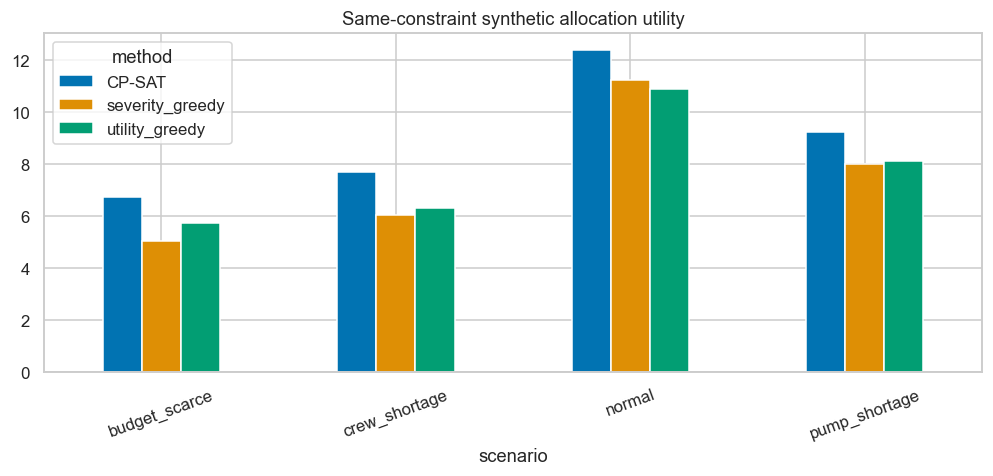

In [11]:
for filename in ['test_alert_rates.csv','injected_summary.csv']:
    path=directory_for(ROOT,'infrastructure_anomaly')/filename
    print(filename);display(pd.read_csv(path))
print('Verified municipal fault precision/recall: unavailable; no real fault labels.')
optimizer=comparisons['resource_optimization'];display(optimizer[['scenario','method','status','utility','selected_count','budget_utilization']])
optimizer.pivot(index='scenario',columns='method',values='utility').plot.bar(title='Same-constraint synthetic allocation utility',rot=20);plt.show()

## 09. Calibration and resolution-time evidence

Calibration curves assess how saved probabilities behave in their test populations. They cannot convert simulated labels into real municipal probabilities. Duration is evaluated among completed synthetic interventions only; incomplete work is censored, so selection and censoring limit interpretation.

### Classifiers on their own reliability diagrams

The diagonal is a within-population reference, not operational certification.

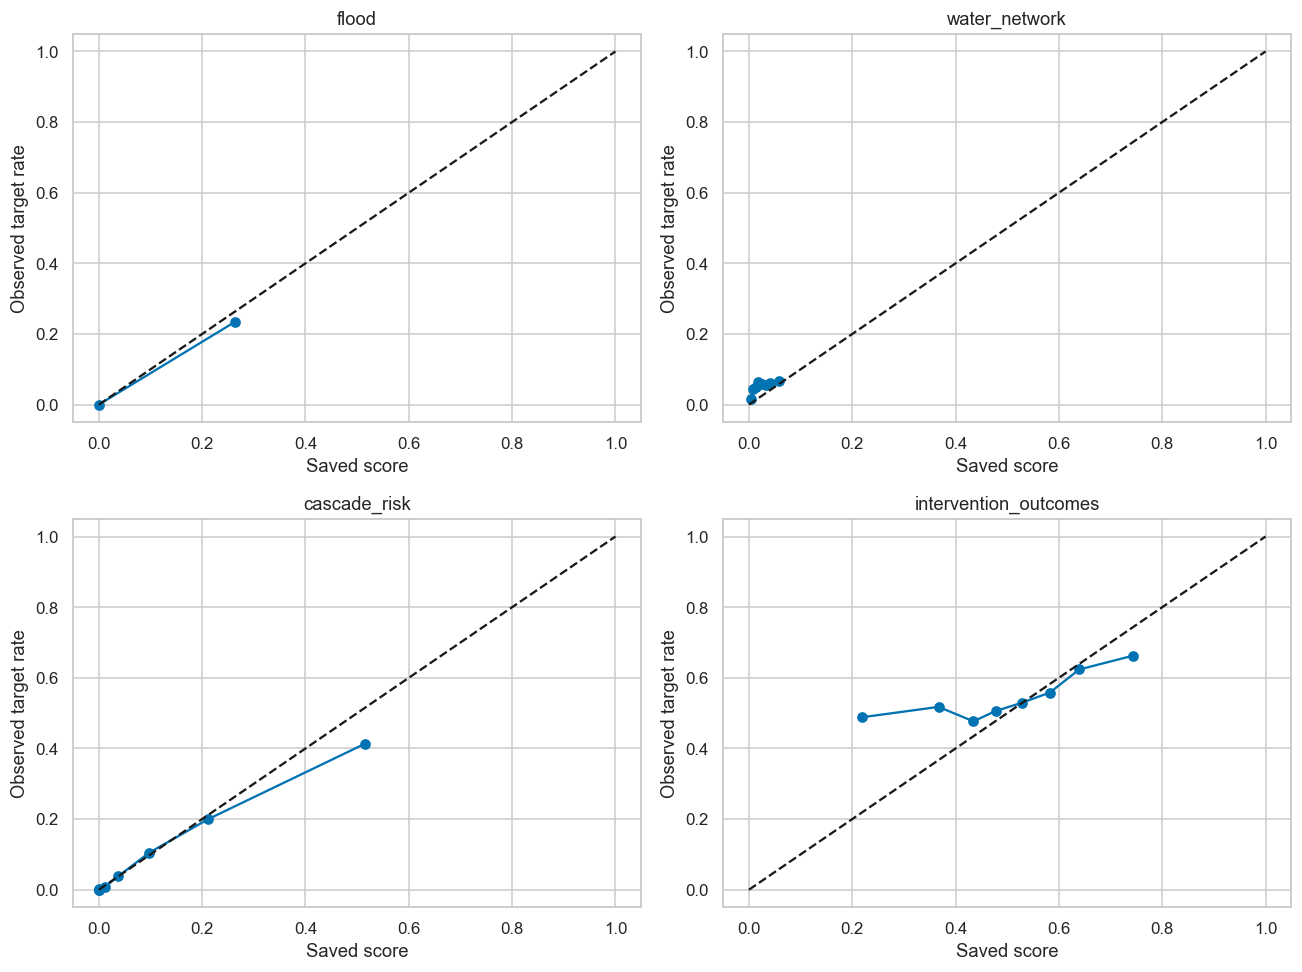

,model,MAE_hours,RMSE_hours
0,Ridge,8.348561,13.953507
1,Random Forest,8.381921,14.110697
2,XGBoost,8.360199,14.056158
3,Train median baseline,9.978897,16.119642


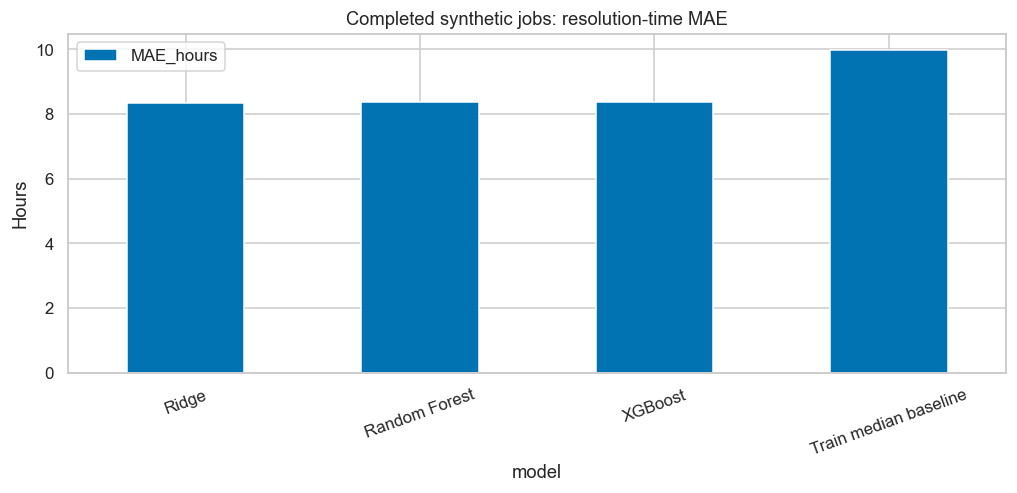

In [12]:
from sklearn.calibration import calibration_curve
fig,axes=plt.subplots(2,2,figsize=(12,9))
for ax,component in zip(axes.flat,['flood','water_network','cascade_risk','intervention_outcomes']):
    table=pd.read_csv(directory_for(ROOT,component)/'test_predictions.csv')
    actual,predicted=calibration_curve(table.target,table.probability,n_bins=8,strategy='quantile')
    ax.plot(predicted,actual,'o-');ax.plot([0,1],[0,1],'k--');ax.set(title=component,xlabel='Saved score',ylabel='Observed target rate')
plt.tight_layout();plt.show()
duration=pd.read_csv(directory_for(ROOT,'intervention_outcomes')/'duration_comparison.csv');display(duration)
duration.plot.bar(x='model',y='MAE_hours',rot=20,title='Completed synthetic jobs: resolution-time MAE');plt.ylabel('Hours');plt.show()

## 10. Artifact and serving readiness matrix

A file existing on disk is insufficient for backend readiness. Fresh-process inference and negative input checks are required. A passing result for synthetic components is classified as simulation/demo only. A technical research-inference result for rainfall, AQI, traffic or anomaly detection still requires source lineage, latency and field validation.

The fresh-process reports are created by Notebook 11. If they do not exist yet or artifact/interface hashes changed, readiness stays Not ready until those checks run.

### Readiness based on evidence, not a manual claim

This matrix makes the remaining scope restrictions visible.

,component,readiness,readiness_reason,validation_status
0,rainfall,Backend-ready for research inference,"Fresh Python process loaded artifact, predicte...",research; measurement lineage and reporting de...
1,aqi,Backend-ready for research inference,"Fresh Python process loaded artifact, predicte...",research; measurement lineage and reporting de...
2,traffic,Backend-ready for research inference,"Fresh Python process loaded artifact, predicte...",research; measurement lineage and reporting de...
3,flood,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",research scenario surrogate; not validated rea...
4,infrastructure_anomaly,Backend-ready for research inference,"Fresh Python process loaded artifact, predicte...",research evidence only
5,water_network,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",weak temporal benchmark; operational abstention
6,cascade_risk,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",unseen synthetic graph holdout; no municipal v...
7,resource_optimization,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",scenario feasibility verified; no real resourc...
8,intervention_outcomes,Simulation/demo only,"Fresh Python process loaded artifact, predicte...",chronological synthetic holdout; unsupported s...


,component,artifact_present,schema_present,fresh_process_passed,observed_validation_claim,operational_authority,simulation_only
0,rainfall,True,True,True,False,False,False
1,aqi,True,True,True,False,False,False
2,traffic,True,True,True,False,False,False
3,flood,True,True,True,False,False,True
4,infrastructure_anomaly,True,True,True,False,False,False
5,water_network,True,True,True,False,False,True
6,cascade_risk,True,True,True,False,False,True
7,resource_optimization,True,True,True,False,False,True
8,intervention_outcomes,True,True,True,False,False,True


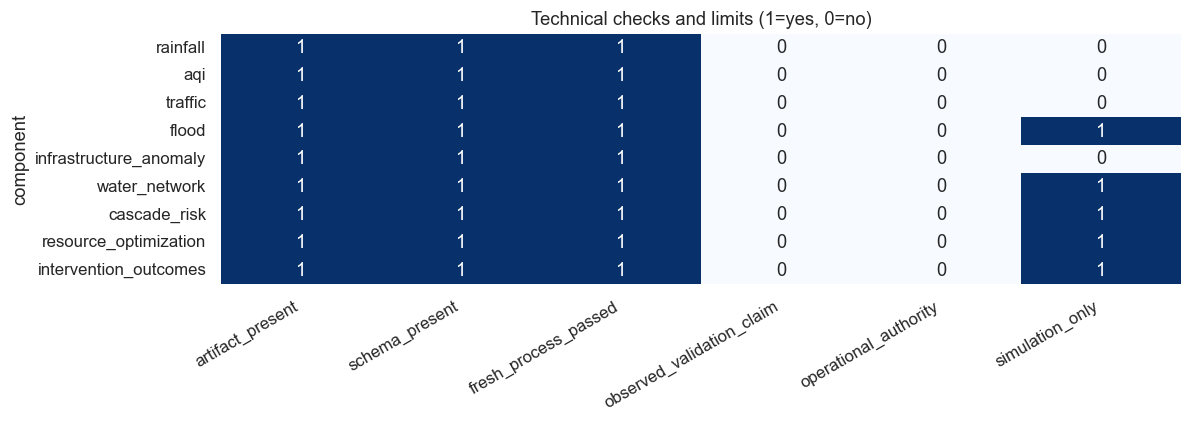

In [13]:
registry=registry_with_checks(ROOT,REPORTS);summary=pd.DataFrame(registry)
readiness=pd.DataFrame({'component':summary.component,'artifact_present':summary.artifact.notna() | summary.component.eq('resource_optimization'),
 'schema_present':summary.feature_schema.notna(),'fresh_process_passed':summary.readiness.ne('Not ready'),'observed_validation_claim':False,
 'operational_authority':False,'simulation_only':summary.simulation_only})
display(summary[['component','readiness','readiness_reason','validation_status']]);display(readiness)
sns.heatmap(readiness.set_index('component').astype(int),annot=True,vmin=0,vmax=1,cmap='Blues',cbar=False);plt.title('Technical checks and limits (1=yes, 0=no)');plt.xticks(rotation=30,ha='right');plt.tight_layout();plt.show()
readiness.to_csv(OUT/'readiness_matrix.csv',index=False)

## 11. Schema compatibility and missing evidence

The shared adapter validates raw input contracts before invoking the existing bundles. Scope, horizon, units, known entities and explicit historical/simulation clocks must agree. Unknown geographic mapping is not fixed by silently joining datasets. Essential standardized metadata for reviewed components is stored beside versioned artifacts; legacy artifacts remain unchanged.

### Validate the reviewed metadata and schemas

Only essential fields are required. Raw flood scores are an acknowledged export limitation, and live city topology/outcome records remain unavailable.

In [14]:
required={'contract_version','component','artifact_version','component_kind','geographic_scope','units','horizon','provenance','supported_inputs','validation_status','operational_supported'}
for component in ['water_network','cascade_risk','resource_optimization','intervention_outcomes']:
    meta=json.loads((directory_for(ROOT,component)/'standard_metadata.json').read_text())
    assert required.issubset(meta),(component,required-set(meta))
    assert meta['operational_supported'] is False
missing=pd.DataFrame([{'component':r['component'],'missing_files':str(r['missing']),'geographic_mapping':'unverified for municipal graph','operational_validation':False} for r in registry])
display(missing);missing.to_csv(OUT/'missing_and_incompatible.csv',index=False)

,component,missing_files,geographic_mapping,operational_validation
0,rainfall,[],unverified for municipal graph,False
1,aqi,[],unverified for municipal graph,False
2,traffic,[],unverified for municipal graph,False
3,flood,[],unverified for municipal graph,False
4,infrastructure_anomaly,[],unverified for municipal graph,False
5,water_network,[],unverified for municipal graph,False
6,cascade_risk,[],unverified for municipal graph,False
7,resource_optimization,[],unverified for municipal graph,False
8,intervention_outcomes,[],unverified for municipal graph,False


## 12. Export the consolidated research registry

The registry records artifact locations, schema paths, identity, version, support scope, horizon, units, validation status and evidence for technical readiness. It does not create missing estimators or rank incompatible tasks. Metadata and metrics are exported as reports for a future thin FastAPI route.

### Save registry and evaluation report

JSON exports reject nonfinite numbers through the shared serializer.

In [15]:
(OUT/'model_registry.json').write_text(json.dumps(json_safe(registry),indent=2,allow_nan=False))
(OUT/'metadata.json').write_text(json.dumps({'component':'model_validation_report','version':'1.0.0','retrained_models':0,'components':len(registry),
 'metric_mismatches':int(metric_checks.status.eq('MISMATCH').sum()),'unavailable_recomputations':int(metric_checks.status.ne('consistent').sum()),
 'limitations':['raw flood probabilities were not exported','no verified municipal topology or outcomes','research readiness is not operational validation']},indent=2))
print('Registry:',OUT/'model_registry.json')

Registry: /Users/jiyahooda/Documents/New project/civicflux_ml/artifacts/model_validation/v1.0.0/model_registry.json


## 13. Conclusions and next validation

Read task baselines and uncertainty together. Repaired thresholds change alert tradeoffs, not discrimination. Water still has excessive false alarms. Cascade performance is simulator-specific and degrades across dependency conditions. Outcome success discrimination remains weak; its latent oracle is a diagnostic, never a deployable feature. Resolution estimates remain conditional on synthetic completion.

The supported next step is controlled research inference through the shared adapter, not deployment as a source of operational municipal facts. Representative measured incidents, verified asset mappings, known sensor units/clocks, independent outcome verification and prospective validation remain necessary.

### Actual audit findings

Results below are read from the files evaluated in this run.

In [16]:
print('Components',len(registry),'metric mismatches',int(metric_checks.status.eq('MISMATCH').sum()))
print('Unavailable recomputations:');display(metric_checks[metric_checks.status.ne('consistent')])
display(summary[['component','readiness']])

Components 9 metric mismatches 0
Unavailable recomputations:


,component,metric,reported,recomputed,absolute_difference,status
17,flood,Brier_raw,0.002063,NaN,NaN,not recomputable from saved predictions


,component,readiness
0,rainfall,Backend-ready for research inference
1,aqi,Backend-ready for research inference
2,traffic,Backend-ready for research inference
3,flood,Simulation/demo only
4,infrastructure_anomaly,Backend-ready for research inference
5,water_network,Simulation/demo only
6,cascade_risk,Simulation/demo only
7,resource_optimization,Simulation/demo only
8,intervention_outcomes,Simulation/demo only
